<a href="https://colab.research.google.com/github/riyagupta2455/working-capital-benchmark/blob/main/working_capital_benchmark.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Working Capital Benchmarking: How Much Cash Is Stuck in the Cash Conversion Cycle?

**Question this project answers:** across a peer set of US packaged food & beverage companies, who runs working capital best, how has that changed over ~10 years, and how much cash could a laggard free up by closing the gap to its peers?

**Why it matters:** working capital is the cheapest source of funding a company has. Every day taken out of the cash conversion cycle (CCC) releases cash that can pay down debt, fund buybacks or go into capex, with no new financing. CFOs, FP&A, treasury, consultants (working-capital diagnostics are a staple engagement) and equity analysts all look at this.

**What the notebook does**

1. Pulls 10 years of audited 10-K data straight from **SEC EDGAR XBRL** (free, no API key)
2. Builds DSO, DIO, DPO, CCC and net working capital as % of sales for each company
3. Benchmarks every company against the peer median and top quartile
4. Sizes the **cash release opportunity** for a target company, by lever
5. Runs a sensitivity: cash freed per day of improvement
6. Exports everything to Excel

| Metric | Formula | Read as |
|---|---|---|
| DSO (days sales outstanding) | avg receivables / revenue × 365 | how long customers take to pay |
| DIO (days inventory outstanding) | avg inventory / COGS × 365 | how long stock sits before it's sold |
| DPO (days payables outstanding) | avg payables / COGS × 365 | how long we take to pay suppliers |
| **CCC** | DSO + DIO − DPO | days of cash tied up in operations |

Lower (even negative) CCC = the business is partly funded by its suppliers.

## 1. Setup and configuration
Change the peer set or target company here. SEC asks every API user to identify themselves, so put your name and email in `USER_AGENT`.

In [31]:
!pip -q install openpyxl

import time, json, requests
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns

pd.set_option("display.float_format", lambda x: f"{x:,.1f}")
sns.set_theme(style="whitegrid", context="notebook")

# ---------------- CONFIG ----------------
USER_AGENT = "Your Name your.email@example.com"   # required by SEC: replace with your own

# US packaged food & beverage peers (all calendar or near-calendar filers except GIS/CPB/SJM/CAG/HRL)
PEERS = ["PEP", "KO", "MDLZ", "KDP", "GIS", "HSY", "KHC", "CAG", "CPB", "SJM", "HRL"]
TARGET = "KHC"            # company we size the cash opportunity for
N_YEARS = 10              # history to keep
BENCHMARK = "median"      # "median" or "top_quartile"
DAYS = 365
EXCLUDE_ACCRUED_AP = True   # drop company-years where payables include accrued liabilities (not comparable)
# ----------------------------------------

HEADERS = {"User-Agent": USER_AGENT, "Accept-Encoding": "gzip, deflate"}
assert "example.com" not in USER_AGENT, "Set USER_AGENT to your own name + email first (SEC requirement)."

## 2. Pull the data from SEC EDGAR

Two endpoints:
- `company_tickers.json` maps tickers to CIK numbers (SEC's company ID)
- `companyfacts/CIK##########.json` returns every XBRL fact the company has ever reported

**The messy part (and a good interview talking point):** companies don't all use the same XBRL tag. Coca-Cola and PepsiCo label receivables differently, some report `Revenues` and others `RevenueFromContractWithCustomer...`. So for each line item we try a ranked list of tags and take the first one that has data for each year.

In [32]:
def get_json(url, retries=3):
    for i in range(retries):
        r = requests.get(url, headers=HEADERS, timeout=30)
        if r.status_code == 200:
            return r.json()
        time.sleep(1 + i)
    r.raise_for_status()

tickers = get_json("https://www.sec.gov/files/company_tickers.json")
TICKER_TO_CIK = {v["ticker"]: str(v["cik_str"]).zfill(10) for v in tickers.values()}
TICKER_TO_NAME = {v["ticker"]: v["title"] for v in tickers.values()}

missing = [t for t in PEERS if t not in TICKER_TO_CIK]
if missing:
    print("Not found on EDGAR (delisted/acquired?), dropping:", missing)
PEERS = [t for t in PEERS if t in TICKER_TO_CIK]

facts = {}
for t in PEERS:
    facts[t] = get_json(f"https://data.sec.gov/api/xbrl/companyfacts/CIK{TICKER_TO_CIK[t]}.json")
    time.sleep(0.15)   # SEC allows max 10 requests/sec
print(f"Downloaded company facts for {len(facts)} companies")

Downloaded company facts for 11 companies


### Tag map and extraction logic

- **Flow items** (revenue, COGS) cover a period: keep only ~1-year durations from 10-K filings.
- **Stock items** (receivables, inventory, payables) are balances at a date: keep 10-K values at the fiscal year-end.
- If a number was restated in a later 10-K, the latest filing wins.

In [33]:
TAGS = {
    "revenue": ["RevenueFromContractWithCustomerExcludingAssessedTax", "Revenues",
                "SalesRevenueNet", "SalesRevenueGoodsNet", "RevenueFromContractWithCustomerIncludingAssessedTax"],
    "cogs":    ["CostOfGoodsAndServicesSold", "CostOfRevenue", "CostOfGoodsSold",
                "CostOfGoodsAndServiceExcludingDepreciationDepletionAndAmortization"],
    "receivables": ["AccountsReceivableNetCurrent", "AccountsAndNotesReceivableNetCurrent",
                    "AccountsNotesAndLoansReceivableNetCurrent", "ReceivablesNetCurrent"],
    "inventory":   ["InventoryNet", "InventoryGross"],
    "payables":    ["AccountsPayableCurrent", "AccountsPayableTradeCurrent",
                    "AccountsPayableAndAccruedLiabilitiesCurrent"],
}
FLOW_ITEMS = {"revenue", "cogs"}

def tag_series(cf, tag, flow):
    # Return {fiscal_year_end_date: value} for one XBRL tag from 10-K filings.
    node = cf["facts"].get("us-gaap", {}).get(tag)
    if not node or "USD" not in node["units"]:
        return pd.Series(dtype=float)
    df = pd.DataFrame(node["units"]["USD"])
    df = df[df["form"].isin(["10-K", "10-K/A"])].copy()
    df["end"] = pd.to_datetime(df["end"])
    if flow:
        if "start" not in df:
            return pd.Series(dtype=float)
        df["days"] = (df["end"] - pd.to_datetime(df["start"])).dt.days
        df = df[df["days"].between(340, 380)]
    df = df.sort_values("filed").drop_duplicates("end", keep="last")   # latest filing wins
    return df.set_index("end")["val"].astype(float)

def item_series(cf, item):
    # Combine ranked tags: first tag with a value for a given date wins. Also record which tag was used.
    vals, srcs = {}, {}
    for tag in TAGS[item]:
        for d, v in tag_series(cf, tag, item in FLOW_ITEMS).items():
            if d not in vals:
                vals[d], srcs[d] = v, tag
    return pd.Series(vals, dtype=float).sort_index(), pd.Series(srcs, dtype=object).sort_index()

rows, tag_log = [], []
for t, cf in facts.items():
    series = {}
    for item in TAGS:
        s, src = item_series(cf, item)
        series[item] = s
        if item == "payables":
            ap_src = src
        for d, tg in src.items():
            tag_log.append({"ticker": t, "item": item, "fy_end": d, "tag": tg})
    fy_ends = series["revenue"].index           # fiscal year-ends defined by annual revenue
    df = pd.DataFrame({k: v.reindex(fy_ends) for k, v in series.items()})
    if EXCLUDE_ACCRUED_AP:   # blank out payables that include accruals, so DPO/CCC isn't overstated
        bad = ap_src[ap_src == "AccountsPayableAndAccruedLiabilitiesCurrent"].index
        df.loc[df.index.isin(bad), "payables"] = np.nan
    df["ticker"] = t
    rows.append(df.rename_axis("fy_end").reset_index())

raw = pd.concat(rows, ignore_index=True)
# fiscal year label: 52/53-week years ending in early Jan belong to the prior year
raw["fy"] = (raw["fy_end"] - pd.Timedelta(days=15)).dt.year
raw = raw.sort_values(["ticker", "fy"]).drop_duplicates(["ticker", "fy"], keep="last")
raw = raw[raw["fy"] > raw["fy"].max() - N_YEARS - 1]   # keep one extra year for averaging
tag_log = pd.DataFrame(tag_log)

print("Coverage (non-missing years per item):")
display(raw.groupby("ticker")[list(TAGS)].count())

Coverage (non-missing years per item):


,revenue,cogs,receivables,inventory,payables
ticker,,,,,
CAG,11,11,11,11,11
CPB,11,11,11,11,11
GIS,11,11,11,11,11
HRL,10,10,10,10,10
HSY,10,10,10,10,10
KDP,10,10,10,10,10
KHC,10,10,10,10,10
KO,10,10,10,10,10
MDLZ,10,10,10,10,10


### Data quality check
Always look at which tag fed each number. `AccountsPayableAndAccruedLiabilitiesCurrent` lumps accruals in with trade payables and will **overstate DPO**. Flag it rather than silently trusting it.

With `EXCLUDE_ACCRUED_AP = True` (the default) those company-years are blanked out, so they show as gaps in the heatmap rather than as fake improvements. Because DPO uses average balances, the year right after an excluded year also drops out.

In [34]:
used = tag_log.groupby(["ticker", "item"])["tag"].agg(lambda x: x.value_counts().index[0]).unstack()
display(used)

flagged = tag_log[tag_log["tag"] == "AccountsPayableAndAccruedLiabilitiesCurrent"]["ticker"].unique()
if len(flagged):
    yrs = (tag_log[tag_log["tag"] == "AccountsPayableAndAccruedLiabilitiesCurrent"]
           .groupby("ticker")["fy_end"].apply(lambda s: sorted(s.dt.year.tolist())).to_dict())
    if EXCLUDE_ACCRUED_AP:
        print("Excluded from DPO/CCC (payables include accrued liabilities), by fiscal year-end:", yrs)
    else:
        print("Caution: payables include accrued liabilities ->", yrs, "-> DPO overstated in those years")

item,cogs,inventory,payables,receivables,revenue
ticker,,,,,
CAG,CostOfGoodsAndServicesSold,InventoryNet,AccountsPayableCurrent,ReceivablesNetCurrent,RevenueFromContractWithCustomerExcludingAssess...
CPB,CostOfGoodsAndServicesSold,InventoryNet,AccountsPayableCurrent,AccountsReceivableNetCurrent,Revenues
GIS,CostOfGoodsAndServicesSold,InventoryNet,AccountsPayableCurrent,ReceivablesNetCurrent,RevenueFromContractWithCustomerExcludingAssess...
HRL,CostOfGoodsAndServicesSold,InventoryNet,AccountsPayableCurrent,AccountsReceivableNetCurrent,SalesRevenueNet
HSY,CostOfGoodsAndServicesSold,InventoryNet,AccountsPayableCurrent,AccountsReceivableNetCurrent,RevenueFromContractWithCustomerExcludingAssess...
KDP,CostOfGoodsSold,InventoryNet,AccountsPayableCurrent,AccountsReceivableNetCurrent,SalesRevenueNet
KHC,CostOfGoodsAndServicesSold,InventoryNet,AccountsPayableTradeCurrent,AccountsReceivableNetCurrent,RevenueFromContractWithCustomerIncludingAssess...
KO,CostOfGoodsAndServicesSold,InventoryNet,AccountsPayableTradeCurrent,AccountsReceivableNetCurrent,Revenues
MDLZ,CostOfGoodsAndServicesSold,InventoryNet,AccountsPayableCurrent,AccountsReceivableNetCurrent,Revenues


Excluded from DPO/CCC (payables include accrued liabilities), by fiscal year-end: {'KO': [2008], 'PEP': [2008]}


## 3. Build the metrics

Using **average balances** (opening + closing ÷ 2) instead of year-end balances. Year-end balances get window-dressed (companies push collections and delay payments around 31 Dec), so averages are a fairer read. The first year of each company is dropped because it has no opening balance.

In [35]:
def build_metrics(raw):
    d = raw.sort_values(["ticker", "fy"]).copy()
    for b in ["receivables", "inventory", "payables"]:
        d[f"avg_{b}"] = d.groupby("ticker")[b].transform(lambda s: (s + s.shift(1)) / 2)
    d["DSO"] = d["avg_receivables"] / d["revenue"] * DAYS
    d["DIO"] = d["avg_inventory"] / d["cogs"] * DAYS
    d["DPO"] = d["avg_payables"] / d["cogs"] * DAYS
    d["CCC"] = d["DSO"] + d["DIO"] - d["DPO"]
    d["trade_wc"] = d["receivables"] + d["inventory"] - d["payables"]
    d["trade_wc_pct_sales"] = d["trade_wc"] / d["revenue"] * 100
    d["gross_margin_pct"] = (1 - d["cogs"] / d["revenue"]) * 100
    return d.dropna(subset=["CCC"])

m = build_metrics(raw)
LATEST = int(m.groupby("ticker")["fy"].max().min())   # latest year every company has reported
print(f"Metrics for {m['ticker'].nunique()} companies, FY{m['fy'].min()}-FY{m['fy'].max()}; common latest year = FY{LATEST}")

latest = m[m["fy"] == LATEST].set_index("ticker")
cols = ["revenue", "DSO", "DIO", "DPO", "CCC", "trade_wc_pct_sales", "gross_margin_pct"]
view = latest[cols].copy()
view["revenue"] = view["revenue"] / 1e9
view = view.rename(columns={"revenue": "revenue_$bn", "trade_wc_pct_sales": "tradeWC_%sales", "gross_margin_pct": "GM_%"})
view = view.sort_values("CCC")
stats = view[["DSO", "DIO", "DPO", "CCC"]].agg(["median"]).rename(index={"median": "PEER MEDIAN"})
display(pd.concat([view, stats]))

Metrics for 11 companies, FY2017-FY2026; common latest year = FY2025


,revenue_$bn,DSO,DIO,DPO,CCC,tradeWC_%sales,GM_%
MDLZ,38.5,36.8,54.5,129.4,-38.1,-4.7,28.4
KDP,16.6,34.9,72.8,143.5,-35.9,2.5,54.2
GIS,19.5,32.7,54.5,114.4,-27.2,-1.6,34.6
PEP,93.9,42.4,47.3,96.2,-6.5,6.0,54.1
KO,47.9,25.2,90.8,110.3,5.7,3.8,61.6
KHC,24.9,32.2,71.8,93.2,10.8,4.5,33.3
SJM,8.7,28.3,76.8,89.7,15.5,6.2,38.8
CPB,10.3,20.1,71.9,67.6,24.4,6.2,30.4
HSY,11.7,23.9,63.0,56.7,30.2,7.7,33.5
CAG,11.6,25.8,85.4,65.4,45.9,10.6,25.9


## 4. Peer benchmarking visuals

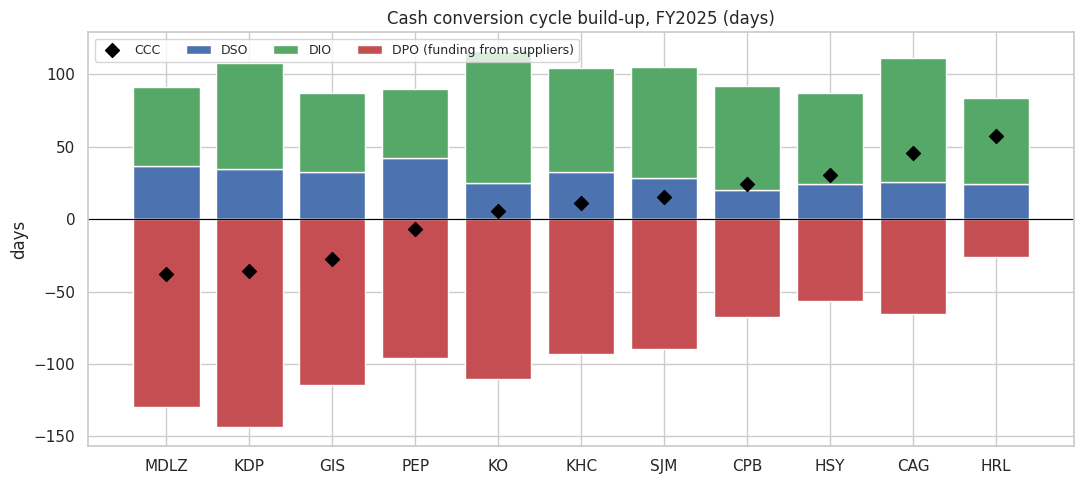

In [36]:
# 4a. CCC decomposition, latest year
order = latest.sort_values("CCC").index
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(order, latest.loc[order, "DSO"], label="DSO", color="#4C72B0")
ax.bar(order, latest.loc[order, "DIO"], bottom=latest.loc[order, "DSO"], label="DIO", color="#55A868")
ax.bar(order, -latest.loc[order, "DPO"], label="DPO (funding from suppliers)", color="#C44E52")
ax.scatter(order, latest.loc[order, "CCC"], color="black", zorder=5, label="CCC", s=50, marker="D")
ax.axhline(0, color="black", lw=0.8)
ax.set_title(f"Cash conversion cycle build-up, FY{LATEST} (days)")
ax.set_ylabel("days"); ax.legend(loc="upper left", ncol=4, fontsize=9)
plt.tight_layout(); plt.show()

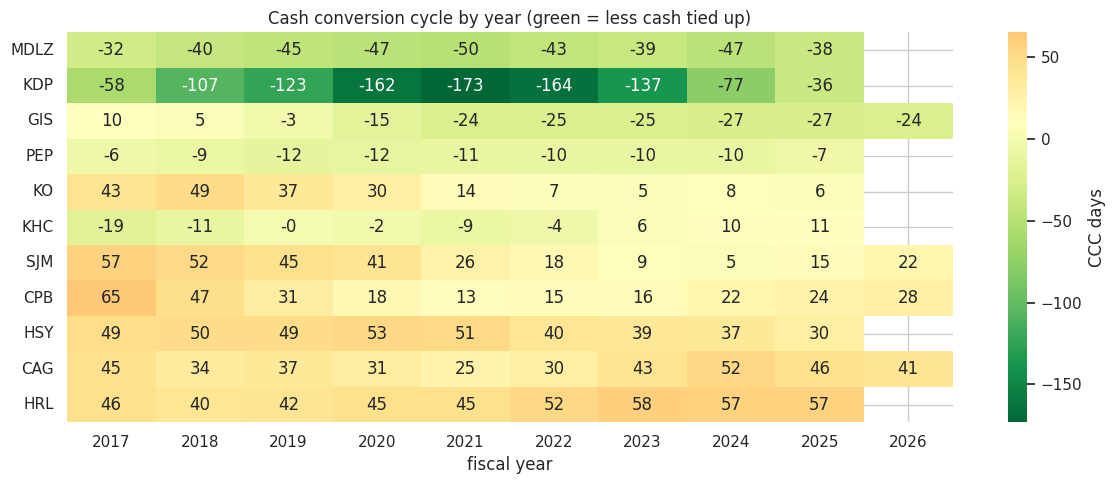

In [37]:
# 4b. CCC heatmap over time: who improved, who slipped
pivot = m.pivot_table(index="ticker", columns="fy", values="CCC")
pivot = pivot.loc[pivot[LATEST].sort_values().index]
plt.figure(figsize=(12, 5))
sns.heatmap(pivot, annot=True, fmt=".0f", cmap="RdYlGn_r", center=pivot.stack().median(), cbar_kws={"label": "CCC days"})
plt.title("Cash conversion cycle by year (green = less cash tied up)")
plt.xlabel("fiscal year"); plt.ylabel("")
plt.tight_layout(); plt.show()

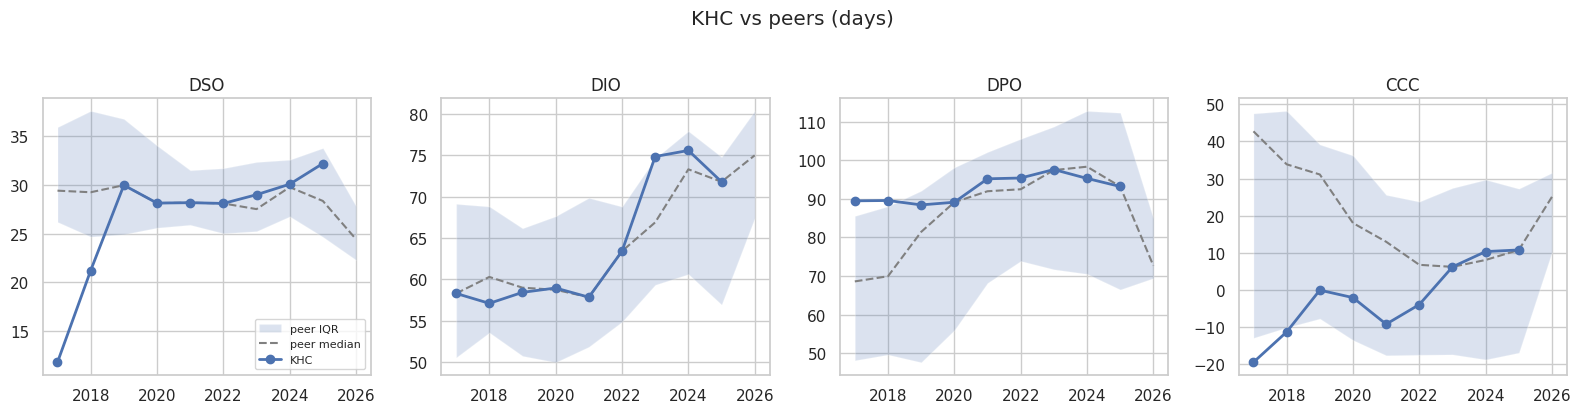

In [38]:
# 4c. Target vs peer median and interquartile band, each component
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharex=True)
for ax, metric in zip(axes, ["DSO", "DIO", "DPO", "CCC"]):
    g = m.groupby("fy")[metric]
    ax.fill_between(g.median().index, g.quantile(0.25), g.quantile(0.75), alpha=0.2, label="peer IQR")
    ax.plot(g.median(), "--", color="grey", label="peer median")
    tgt = m[m["ticker"] == TARGET].set_index("fy")[metric]
    ax.plot(tgt, marker="o", lw=2, label=TARGET)
    ax.set_title(metric)
axes[0].legend(fontsize=8)
fig.suptitle(f"{TARGET} vs peers (days)", y=1.03)
plt.tight_layout(); plt.show()

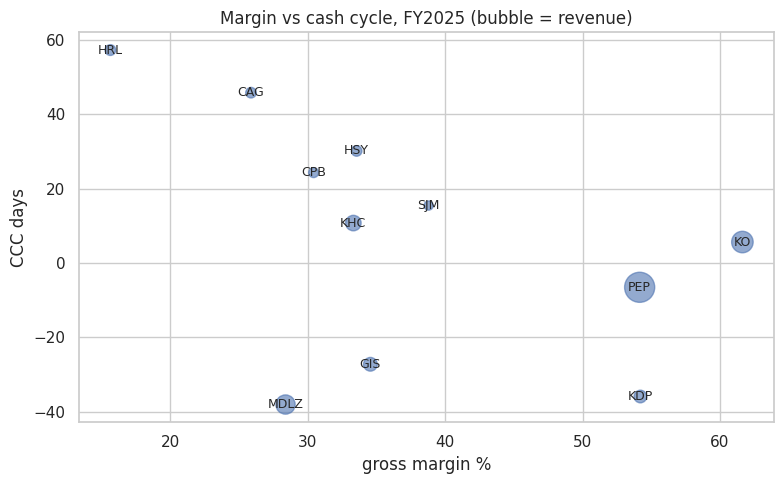

In [39]:
# 4d. Does scale or margin explain working capital? (quick look, not a causal claim)
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(latest["gross_margin_pct"], latest["CCC"], s=latest["revenue"] / 2e8, alpha=0.6)
for t, r in latest.iterrows():
    ax.annotate(t, (r["gross_margin_pct"], r["CCC"]), fontsize=9, ha="center", va="center")
ax.set_xlabel("gross margin %"); ax.set_ylabel("CCC days")
ax.set_title(f"Margin vs cash cycle, FY{LATEST} (bubble = revenue)")
plt.tight_layout(); plt.show()

## 5. Sizing the cash opportunity for the target

For each lever, compare the target to the benchmark and convert the day gap into dollars:

- Receivables: `(DSO_target − DSO_benchmark) × revenue / 365`
- Inventory: `(DIO_target − DIO_benchmark) × COGS / 365`
- Payables: `(DPO_benchmark − DPO_target) × COGS / 365` (here the benchmark is *higher* days)

Only gaps where the target is worse count. If it's already better than peers, the opportunity for that lever is zero, not negative.

In [40]:
def benchmark(series, kind, higher_is_better=False):
    if kind == "median":
        return series.median()
    q = 0.75 if higher_is_better else 0.25
    return series.quantile(q)

def cash_opportunity(ticker, year=LATEST, kind=BENCHMARK):
    peers = m[(m["fy"] == year) & (m["ticker"] != ticker)]
    t = m[(m["fy"] == year) & (m["ticker"] == ticker)].iloc[0]
    out = []
    for metric, base, hib, label in [("DSO", "revenue", False, "Receivables (collect faster)"),
                                     ("DIO", "cogs", False, "Inventory (hold less)"),
                                     ("DPO", "cogs", True, "Payables (pay later)")]:
        bm = benchmark(peers[metric], kind, hib)
        gap = (bm - t[metric]) if hib else (t[metric] - bm)
        cash = max(gap, 0) * t[base] / DAYS
        out.append({"lever": label, "target_days": t[metric], "benchmark_days": bm,
                    "gap_days": gap, "cash_release_$m": cash / 1e6})
    df = pd.DataFrame(out)
    return df, t

opp, t_row = cash_opportunity(TARGET)
total = opp["cash_release_$m"].sum()
display(opp)
print(f"\n{TARGET}: closing the gap to peer {BENCHMARK} would release about ${total:,.0f}m of cash "
      f"({total*1e6 / t_row['revenue']*100:.1f}% of revenue, {total*1e6 / t_row['trade_wc']*100 if t_row['trade_wc']>0 else float('nan'):.0f}% of trade working capital).")

,lever,target_days,benchmark_days,gap_days,cash_release_$m
0,Receivables (collect faster),32.2,27.1,5.1,350.3
1,Inventory (hold less),71.8,67.5,4.3,197.6
2,Payables (pay later),93.2,92.9,-0.3,0.0



KHC: closing the gap to peer median would release about $548m of cash (2.2% of revenue, 49% of trade working capital).


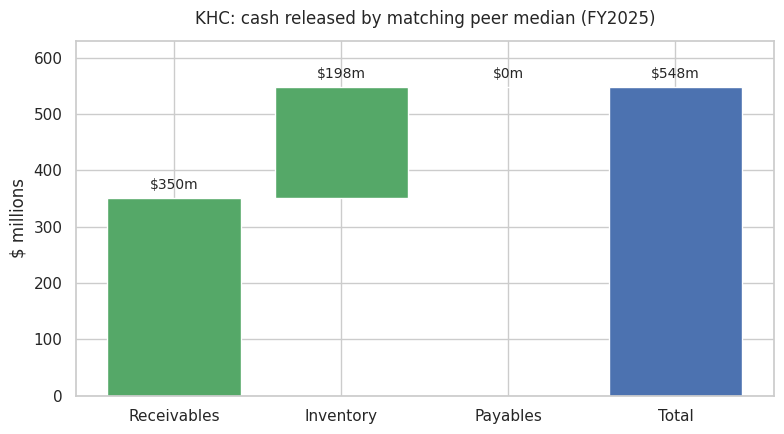

In [41]:
# Waterfall: where the cash comes from
vals = opp["cash_release_$m"].tolist()
labels = [l.split(" (")[0] for l in opp["lever"]] + ["Total"]
starts = np.concatenate([[0], np.cumsum(vals)[:-1]])
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar(labels[:-1], vals, bottom=starts, color="#55A868")
ax.bar(labels[-1], total, color="#4C72B0")
pad = max(total, 1) * 0.02
for i, v in enumerate(vals + [total]):
    top = starts[i] + v if i < len(vals) else total
    ax.text(i, top + pad, f"${v:,.0f}m", ha="center", va="bottom", fontsize=10)
ax.set_ylim(0, max(total, 1) * 1.15)   # headroom so value labels don't run into the title
ax.set_ylabel("$ millions")
ax.set_title(f"{TARGET}: cash released by matching peer {BENCHMARK} (FY{LATEST})", pad=12)
plt.tight_layout(); plt.show()

In [42]:
# Run the same sizing for every company: the peer-wide picture
summary = []
for tk in m["ticker"].unique():
    for kind in ["median", "top_quartile"]:
        o, r = cash_opportunity(tk, kind=kind)
        summary.append({"ticker": tk, "benchmark": kind, "cash_release_$m": o["cash_release_$m"].sum(),
                        "pct_revenue": o["cash_release_$m"].sum() * 1e6 / r["revenue"] * 100})
opp_all = pd.DataFrame(summary).pivot(index="ticker", columns="benchmark", values=["cash_release_$m", "pct_revenue"])
display(opp_all.sort_values(("cash_release_$m", "median"), ascending=False))

cash_release_$m              pct_revenue             
benchmark          median top_quartile      median top_quartile
ticker                                                         
PEP               3,952.2      6,667.9         4.2          7.1
HRL               1,916.8      2,516.4        15.8         20.8
KO                1,178.9      1,843.4         2.5          3.8
CAG               1,116.9      1,877.4         9.6         16.2
MDLZ              1,029.9      1,311.4         2.7          3.4
HSY                 808.7      1,361.7         6.9         11.6
CPB                 617.1      1,210.5         6.0         11.8
KHC                 547.9      2,183.8         2.2          8.8
KDP                 466.6        831.1         2.8          5.0
GIS                 300.5        442.9         1.5          2.3
SJM                 211.2        749.8         2.4          8.6

## 6. Sensitivity: what is one day worth?

Management rarely closes the whole gap at once. This shows the cash freed for each day of improvement on each lever, which is how a CFO would frame a target ("take 5 days out of DIO next year").

In [43]:
day_value = pd.DataFrame({
    "1 day DSO ($m)": latest["revenue"] / DAYS / 1e6,
    "1 day DIO/DPO ($m)": latest["cogs"] / DAYS / 1e6,
})
display(day_value.sort_values("1 day DSO ($m)", ascending=False))

tr = latest.loc[TARGET]
grid = pd.DataFrame({f"{d} days CCC": [d * tr["cogs"] / DAYS / 1e6] for d in [5, 10, 15, 20]}, index=[TARGET])
print("Cash from cutting CCC via DIO/DPO levers ($m):"); display(grid)

,1 day DSO ($m),1 day DIO/DPO ($m)
ticker,,
PEP,257.3,118.0
KO,131.3,50.4
MDLZ,105.6,75.6
KHC,68.3,45.6
GIS,53.4,34.9
KDP,45.5,20.8
HRL,33.2,28.0
HSY,32.0,21.3
CAG,31.8,23.6


Cash from cutting CCC via DIO/DPO levers ($m):


,5 days CCC,10 days CCC,15 days CCC,20 days CCC
KHC,227.8,455.7,683.5,911.4


## 7. Auto-generated takeaways

In [44]:
best, worst = latest["CCC"].idxmin(), latest["CCC"].idxmax()
first = m.groupby("ticker")["fy"].min()
chg = {tk: m[(m.ticker == tk) & (m.fy == LATEST)]["CCC"].iloc[0] - m[(m.ticker == tk) & (m.fy == first[tk])]["CCC"].iloc[0]
       for tk in latest.index}
chg = pd.Series(chg).sort_values()
biggest_lever = opp.loc[opp["cash_release_$m"].idxmax(), "lever"]

print(f"- Best-in-class CCC in FY{LATEST}: {best} at {latest.loc[best,'CCC']:.0f} days; worst: {worst} at {latest.loc[worst,'CCC']:.0f} days.")
print(f"- Peer median CCC: {latest['CCC'].median():.0f} days (DSO {latest['DSO'].median():.0f}, DIO {latest['DIO'].median():.0f}, DPO {latest['DPO'].median():.0f}).")
print(f"- Most improved since start of window: {chg.index[0]} ({chg.iloc[0]:+.0f} days); most deteriorated: {chg.index[-1]} ({chg.iloc[-1]:+.0f} days).")
print(f"- {TARGET}'s biggest lever vs peer {BENCHMARK}: {biggest_lever}; total opportunity ≈ ${total:,.0f}m.")
print(f"- {sum(latest['CCC'] < 0)} of {len(latest)} companies run a negative CCC, i.e. suppliers fund part of their operations.")

- Best-in-class CCC in FY2025: MDLZ at -38 days; worst: HRL at 57 days.
- Peer median CCC: 11 days (DSO 28, DIO 72, DPO 93).
- Most improved since start of window: SJM (-41 days); most deteriorated: KHC (+30 days).
- KHC's biggest lever vs peer median: Receivables (collect faster); total opportunity ≈ $548m.
- 4 of 11 companies run a negative CCC, i.e. suppliers fund part of their operations.


## 8. Export

In [45]:
with pd.ExcelWriter("working_capital_benchmark.xlsx") as xw:
    m.to_excel(xw, sheet_name="metrics_by_year", index=False)
    view.to_excel(xw, sheet_name=f"peer_table_FY{LATEST}")
    opp.to_excel(xw, sheet_name=f"opportunity_{TARGET}", index=False)
    opp_all.to_excel(xw, sheet_name="opportunity_all")
    used.to_excel(xw, sheet_name="xbrl_tags_used")
print("Saved working_capital_benchmark.xlsx (Colab: Files panel on the left -> download)")

Saved working_capital_benchmark.xlsx (Colab: Files panel on the left -> download)


## 9. Limitations (say these before an interviewer does)

- **Reported tags aren't always comparable.** Some receivables lines include non-trade items; some payables include accruals. The tag log in section 2 makes this visible.
- **Supply-chain finance** (reverse factoring) inflates DPO for some companies and is only partly disclosed in footnotes.
- **Receivables factoring/securitisation** lowers DSO without changing customer behaviour.
- **Fiscal year-ends differ** (GIS ends in May, most others in December), so seasonal inventory peaks fall in different places.
- **M&A** (e.g. KDP's merger, KHC's divestitures) causes jumps in averages; the year after a big deal deserves a footnote.
- **Benchmarking ≠ target-setting.** A company with a different channel mix (e.g. more DSD, more emerging markets) can have a legitimately different cycle.

## 10. Ideas to extend it

- Compare a different sector (`PEERS = ["WMT","TGT","COST","KR","DG"]` for retail, where CCC is often negative)
- Add quarterly data (filter `fp` in Q1–Q3 from 10-Qs) to show seasonality
- Link CCC to free cash flow conversion or ROIC
- Turn section 5 into a Streamlit app where the user picks the target and benchmark